In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

REPORT_DIR = Path(".")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif", "font.size": 11,
    "axes.labelsize": 12, "legend.fontsize": 9,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

## Q1 Data — Producer-Consumer Benchmark (macOS run, x86 Linux for grading)

In [2]:
# P = number of producers, n*P = 100000 total items always
P_vals = [1, 2, 4, 8, 16, 32]

q1_data = {
    16: {
        "P1": [18665, 24923, 24292, 23687, 24691, 25090],
        "P2": [21659, 26046, 45282, 57129, 61456, 60575],
        "P3": [44444, 31196, 59524, 101453, 142222, 142332],
    },
    64: {
        "P1": [16872, 24576, 21870, 23563, 24941, 24472],
        "P2": [16923, 22791, 39001, 55559, 58293, 59915],
        "P3": [43796, 36382, 74318, 99135, 141759, 136922],
    },
    256: {
        "P1": [18566, 25849, 20750, 23513, 24700, 24405],
        "P2": [17194, 25804, 41463, 56867, 59468, 59670],
        "P3": [38592, 35950, 62401, 113395, 138919, 138864],
    },
}

METHOD_COLORS = {
    "P1": "#1f77b4",
    "P2": "#ff7f0e",
    "P3": "#2ca02c",
}
METHOD_LABELS = {
    "P1": "P1: Lock-free sem",
    "P2": "P2: POSIX sem",
    "P3": "P3: Cond var",
}

Saved q1_time.png / .pdf


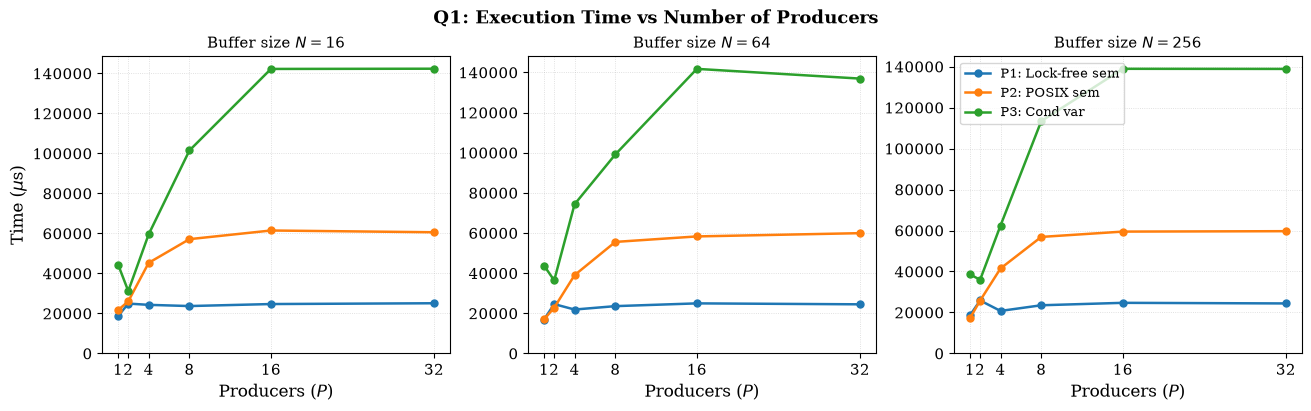

In [3]:
# Figure 1 — Q1 Time vs Producers (3 subplots, one per buffer size N)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True, sharey=False)

for ax, N in zip(axes, [16, 64, 256]):
    for method in ["P1", "P2", "P3"]:
        ax.plot(P_vals, q1_data[N][method],
                color=METHOD_COLORS[method], marker="o", markersize=5,
                linewidth=1.8, label=METHOD_LABELS[method])
    ax.set_title(f"Buffer size $N={N}$", fontsize=11)
    ax.set_xlabel("Producers ($P$)")
    ax.set_ylabel(r"Time ($\mu$s)" if N == 16 else "")
    ax.set_xticks(P_vals)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    if N == 256:
        ax.legend(loc="upper left", frameon=True)

fig.suptitle("Q1: Execution Time vs Number of Producers", fontsize=13, fontweight="bold")
for ext in ("png", "pdf"):
    fig.savefig(REPORT_DIR / f"q1_time.{ext}", dpi=300, bbox_inches="tight")
print("Saved q1_time.png / .pdf")
plt.show()

Saved q1_speedup.png / .pdf


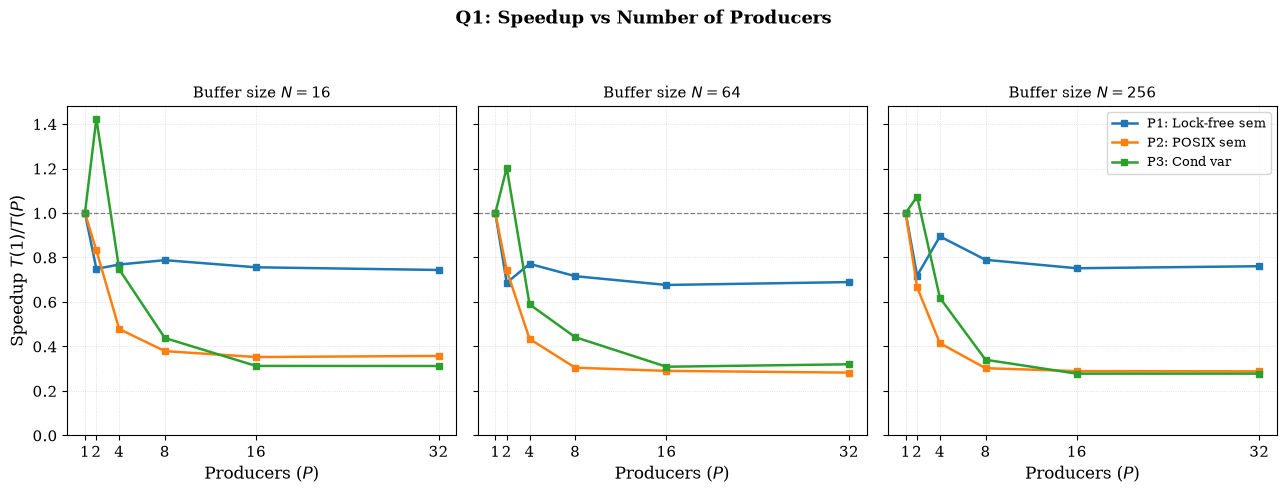

In [4]:
# Figure 2 — Q1 Speedup vs Producers (T_P1 / T_P)
fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)

for ax, N in zip(axes, [16, 64, 256]):
    for method in ["P1", "P2", "P3"]:
        base = q1_data[N][method][0]
        speedups = [base / t for t in q1_data[N][method]]
        ax.plot(P_vals, speedups,
                color=METHOD_COLORS[method], marker="s", markersize=5,
                linewidth=1.8, label=METHOD_LABELS[method])
    ax.axhline(1.0, color="0.5", linestyle="--", linewidth=0.9)
    ax.set_title(f"Buffer size $N={N}$", fontsize=11)
    ax.set_xlabel("Producers ($P$)")
    ax.set_ylabel(r"Speedup $T(1)/T(P)$" if N == 16 else "")
    ax.set_xticks(P_vals)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    if N == 256:
        ax.legend(loc="upper right", frameon=True)

fig.suptitle("Q1: Speedup vs Number of Producers", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
for ext in ("png", "pdf"):
    fig.savefig(REPORT_DIR / f"q1_speedup.{ext}", dpi=300, bbox_inches="tight")
print("Saved q1_speedup.png / .pdf")
plt.show()

## Q2 Data — Concurrent Graph Benchmark (Linux x86 run)

In [5]:
T_vals = [1, 2, 4, 8, 16, 32]

# Time in microseconds for each ops file and each program
q2_time = {
    1: {  # ops file 1: 80% insert, 10% delete, 10% search
        "P1": [747,  2941, 4959, 6067, 6804,  7584],
        "P2": [1163, 2115, 1218,  795,  747,   635],
        "P3": [822,  2822, 4534, 6157, 6838, 11426],
        "P4": [2301, 2654, 1619,  946,  850,   971],
        "P5": [850,  1371,  994,  697,  725,   918],
        "P6": [1132, 1962, 1011,  838,  691,   582],
    },
    2: {  # ops file 2: 30% insert, 30% delete, 40% search
        "P1": [765,  1567, 2599, 3745, 4071, 4632],
        "P2": [1246, 1366,  845,  508,  406,  498],
        "P3": [717,  2748, 3793, 4550, 4827, 4734],
        "P4": [1721, 1753, 1048,  584,  544,  534],
        "P5": [592,   883,  685,  507,  491,  458],
        "P6": [606,   818,  455,  302,  475,  444],
    },
    3: {  # ops file 3: 10% insert, 10% delete, 80% search
        "P1": [195,  831, 1460, 2300, 2272, 2790],
        "P2": [658,  977,  650,  404,  356,  508],
        "P3": [302, 2678, 3251, 3706, 4100, 4036],
        "P4": [1100, 1205,  732,  433,  354,  437],
        "P5": [445,   580,  503,  389,  286,  408],
        "P6": [195,   264,  157,  116,  203,  408],
    },
}

# Throughput in ops/sec (= 16000 / time_us * 1e6)
q2_tp = {}
for fi, progs in q2_time.items():
    q2_tp[fi] = {m: [16000 / t * 1e6 for t in times] for m, times in progs.items()}

PROG_COLORS = {
    "P1": "#d62728",
    "P2": "#1f77b4",
    "P3": "#ff7f0e",
    "P4": "#2ca02c",
    "P5": "#9467bd",
    "P6": "#8c564b",
}
PROG_LABELS = {
    "P1": "P1: Global mutex",
    "P2": "P2: Per-list mutex",
    "P3": "P3: HOH mutex",
    "P4": "P4: HOH rwlock",
    "P5": "P5: HOH CAS spin",
    "P6": "P6: Optimistic CAS",
}
FILE_TITLES = {
    1: "File 1: 80\% insert / 10\% delete / 10\% search",
    2: "File 2: 30\% insert / 30\% delete / 40\% search",
    3: "File 3: 10\% insert / 10\% delete / 80\% search",
}

<>:53: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:54: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:55: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:53: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:54: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:55: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
/var/folders/0l/rn3k0tmn43b2046rmvzlp6f40000gq/T/ipykernel_79542/1597229489.

Saved q2_time.png / .pdf


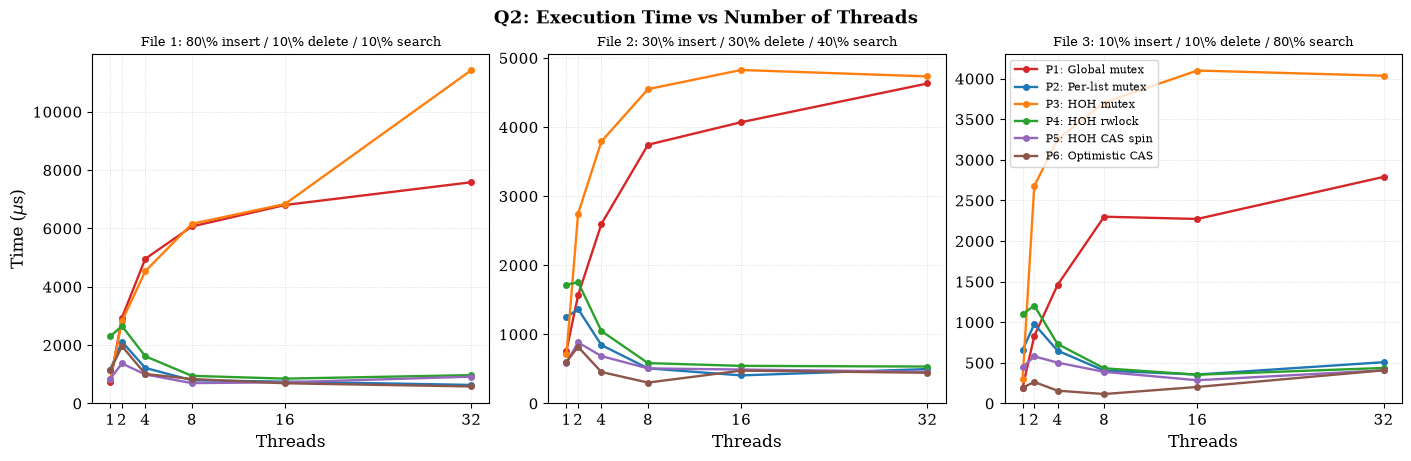

In [6]:
# Figure 3 — Q2 Time vs Threads (3 subplots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True, sharey=False)

for ax, fi in zip(axes, [1, 2, 3]):
    for prog in ["P1","P2","P3","P4","P5","P6"]:
        ax.plot(T_vals, q2_time[fi][prog],
                color=PROG_COLORS[prog], marker="o", markersize=4,
                linewidth=1.7, label=PROG_LABELS[prog])
    ax.set_title(FILE_TITLES[fi], fontsize=9.5)
    ax.set_xlabel("Threads")
    ax.set_ylabel(r"Time ($\mu$s)" if fi == 1 else "")
    ax.set_xticks(T_vals)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    if fi == 3:
        ax.legend(loc="upper left", frameon=True, fontsize=8)

fig.suptitle("Q2: Execution Time vs Number of Threads", fontsize=13, fontweight="bold")
for ext in ("png", "pdf"):
    fig.savefig(REPORT_DIR / f"q2_time.{ext}", dpi=300, bbox_inches="tight")
print("Saved q2_time.png / .pdf")
plt.show()

Saved q2_throughput.png / .pdf


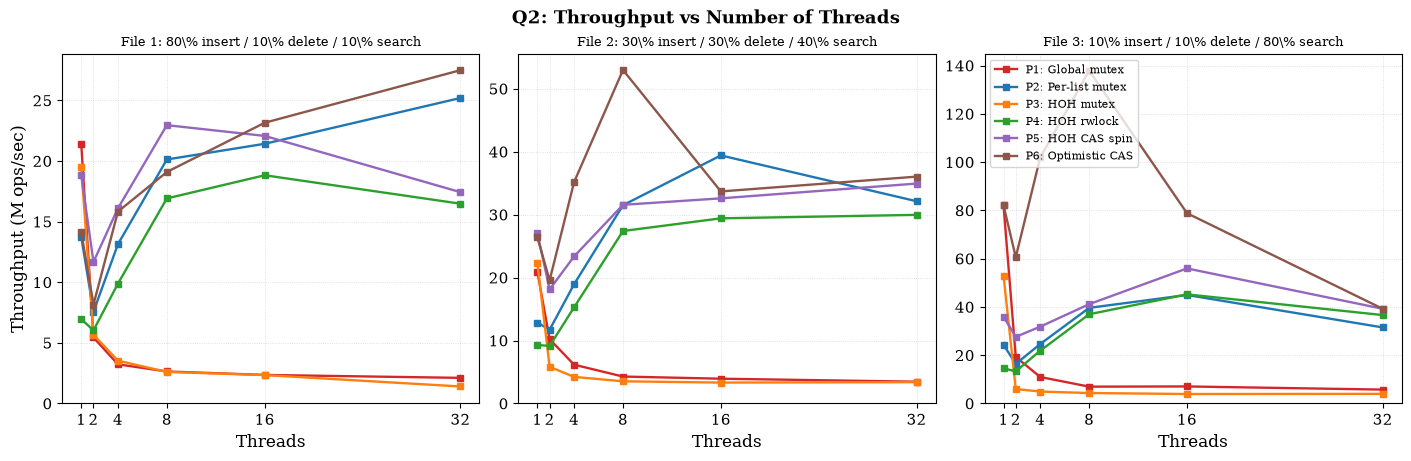

In [7]:
# Figure 4 — Q2 Throughput vs Threads (3 subplots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True, sharey=False)

for ax, fi in zip(axes, [1, 2, 3]):
    for prog in ["P1","P2","P3","P4","P5","P6"]:
        tp_M = [v / 1e6 for v in q2_tp[fi][prog]]   # in millions of ops/sec
        ax.plot(T_vals, tp_M,
                color=PROG_COLORS[prog], marker="s", markersize=4,
                linewidth=1.7, label=PROG_LABELS[prog])
    ax.set_title(FILE_TITLES[fi], fontsize=9.5)
    ax.set_xlabel("Threads")
    ax.set_ylabel("Throughput (M ops/sec)" if fi == 1 else "")
    ax.set_xticks(T_vals)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    if fi == 3:
        ax.legend(loc="upper left", frameon=True, fontsize=8)

fig.suptitle("Q2: Throughput vs Number of Threads", fontsize=13, fontweight="bold")
for ext in ("png", "pdf"):
    fig.savefig(REPORT_DIR / f"q2_throughput.{ext}", dpi=300, bbox_inches="tight")
print("Saved q2_throughput.png / .pdf")
plt.show()

In [ ]:
# Figure 5 — Q2 Speedup vs Threads (3 subplots, speedup = T_1 / T_k)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True, sharey=True)

for ax, fi in zip(axes, [1, 2, 3]):
    for prog in ["P1","P2","P3","P4","P5","P6"]:
        base = q2_time[fi][prog][0]
        sp = [base / t for t in q2_time[fi][prog]]
        ax.plot(T_vals, sp,
                color=PROG_COLORS[prog], marker="^", markersize=4,
                linewidth=1.7, label=PROG_LABELS[prog])
    ax.axhline(1.0, color="0.5", linestyle="--", linewidth=0.9)
    ax.set_title(FILE_TITLES[fi], fontsize=9.5)
    ax.set_xlabel("Threads")
    ax.set_ylabel(r"Speedup $T(1)/T(k)$" if fi == 1 else "")
    ax.set_xticks(T_vals)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    if fi == 3:
        ax.legend(loc="upper left", frameon=True, fontsize=8)

fig.suptitle("Q2: Speedup vs Number of Threads", fontsize=13, fontweight="bold")
for ext in ("png", "pdf"):
    fig.savefig(REPORT_DIR / f"q2_speedup.{ext}", dpi=300, bbox_inches="tight")
print("Saved q2_speedup.png / .pdf")
plt.show()

: 

In [1]:
# Figure 6 — Q2 Speedup comparison across files for best methods (P2, P4, P6)
# Useful for seeing how workload mix affects each strategy
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5), sharey=True)

FILE_COLORS = {1: "#d62728", 2: "#1f77b4", 3: "#2ca02c"}
FILE_MARKERS = {1: "o", 2: "s", 3: "^"}
FILE_LABELS = {
    1: "File 1 (write-heavy)",
    2: "File 2 (balanced)",
    3: "File 3 (read-heavy)",
}

for ax, prog in zip(axes, ["P2", "P4", "P6"]):
    for fi in [1, 2, 3]:
        base = q2_time[fi][prog][0]
        sp = [base / t for t in q2_time[fi][prog]]
        ax.plot(T_vals, sp,
                color=FILE_COLORS[fi], marker=FILE_MARKERS[fi], markersize=5,
                linewidth=1.7, label=FILE_LABELS[fi])
    ax.axhline(1.0, color="0.5", linestyle="--", linewidth=0.9)
    ax.set_title(f"{PROG_LABELS[prog]}", fontsize=10)
    ax.set_xlabel("Threads")
    ax.set_ylabel(r"Speedup $T(1)/T(k)$" if prog == "P2" else "")
    ax.set_xticks(T_vals)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    ax.legend(loc="upper left", frameon=True, fontsize=9)

fig.suptitle("Q2: Speedup by Workload Mix (P2, P4, P6)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
for ext in ("png", "pdf"):
    fig.savefig(REPORT_DIR / f"q2_workload_speedup.{ext}", dpi=300, bbox_inches="tight")
print("Saved q2_workload_speedup.png / .pdf")
plt.show()

NameError: name 'plt' is not defined